# CNN Training - Exercise Binary Classification

Binary classification (correct / incorrect) of exam exercise answers.

**Compared models**: EfficientNetV2-S, EfficientNetV2-M and ConvNeXt-Tiny, pre-trained on ImageNet, with fine-tuning of the classification head.

**Validation**: Stratified 5-Fold Cross Validation, with the same folds for all three models

**Class imbalance handling**: automatically computed class weights

## 1. Imports

In [9]:
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, recall_score,
)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}")

Device: cuda
PyTorch: 2.14.1+cu130


## 2. Configuration

In [ ]:
DATASET_ROOT = "../data/labeled/by_exercise"   # exercises folder sorted into incorrect/correct
OUTPUT_DIR = "../outputs/exercise_cnn"    # output folder for the CNN models
MODEL_NAMES = ["efficientnet_v2_s", "efficientnet_v2_m", "convnext_tiny"]    # CNN models used

# Hyperparameters
IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 30
LEARNING_RATE = 1e-4
N_FOLDS = 5
SEED = 42
UNFREEZE_AT_EPOCH = 15  # unfreeze the last layers after this epoch

def set_seed(seed=SEED):
    torch.manual_seed(seed)
    np.random.seed(seed)

set_seed()

Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

## 3. Loading the dataset

We go through the `by_exercise/q01/correct/`, `by_exercise/q01/incorrect/`, etc. structure to collect all image paths and their labels.

In [11]:
X = np.load("../data/processed/X_exercise.npy")
y = np.load("../data/processed/y_exercise.npy")

print(f"Dataset shape : {X.shape}")
print(f"Correct : {np.sum(y == 1)}")
print(f"Incorrect : {np.sum(y == 0)}")

Dataset shape : (135, 224, 224, 3)
Correct : 96
Incorrect : 39


## 4. PyTorch dataset and augmentation

**Augmentation (training only)**: at each epoch, each image is slightly and randomly modified (rotation ±5°, brightness ±10%, slight noise).

The images are already normalised (ImageNet): we denormalise them back to [0, 1], apply the augmentation, then normalise again.

**Validation**: no augmentation, images are used as they are.

In [12]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def augment(img):
    """Rotation ±5°, brightness ±10%, slight noise on a normalised image (C,H,W)."""
    img = img * STD + MEAN  # back to [0, 1]
    img = transforms.functional.rotate(img, float(np.random.uniform(-5, 5)), fill=[1.0])  # corners filled with white
    img = img * np.random.uniform(0.9, 1.1)
    img = img + torch.randn_like(img) * 0.01
    img = img.clamp(0, 1)
    return (img - MEAN) / STD


class ExamDataset(Dataset):
    def __init__(self, X, y, augment=False):
        self.X = torch.tensor(X, dtype=torch.float32).permute(0, 3, 1, 2)  # (N,H,W,C) → (N,C,H,W)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.augment = augment
    
    def __len__(self):
        return len(self.y)
    
    def __getitem__(self, idx):
        img = self.X[idx]
        if self.augment:
            img = augment(img)
        return img, self.y[idx]

## 5. Models

Three models pre-trained on ImageNet. For each one, the last layer is replaced with the same binary classification head. ConvNeXt keeps its normalisation and its `Flatten` just before this head.

| Model | Parameters (approx.) | ImageNet training resolution |
|---|---|---|
| EfficientNetV2-S | 21 M | 384 px |
| EfficientNetV2-M | 54 M | 480 px |
| ConvNeXt-Tiny | 29 M | 224 px |

Here, all three receive 224×224 images.

**Fine-tuning strategy**:
1. Freeze the whole backbone (pre-trained features)
2. Train only the classification head
3. After a few epochs, unfreeze the last layers of the backbone to refine

In [13]:
MODELS = {
    "efficientnet_v2_s": (models.efficientnet_v2_s, models.EfficientNet_V2_S_Weights.IMAGENET1K_V1),
    "efficientnet_v2_m": (models.efficientnet_v2_m, models.EfficientNet_V2_M_Weights.IMAGENET1K_V1),
    "convnext_tiny": (models.convnext_tiny, models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1),
}


def binary_head(in_features):
    return [
        nn.Dropout(0.3),
        nn.Linear(in_features, 128),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(128, 1),
    ]


def create_model(model_name, unfreeze_last_n=0):
    """Creates the requested model with a binary classification head."""
    builder, weights = MODELS[model_name]
    model = builder(weights=weights)

    # Freeze the backbone
    for param in model.features.parameters():
        param.requires_grad = False

    # Unfreeze the last N blocks if requested
    if unfreeze_last_n > 0:
        for param in model.features[-unfreeze_last_n:].parameters():
            param.requires_grad = True

    # New classification head
    in_features = model.classifier[-1].in_features
    if model_name.startswith("convnext"):
        # Keep LayerNorm2d and Flatten, required before the linear layer
        model.classifier = nn.Sequential(*model.classifier[:-1], *binary_head(in_features))
    else:
        model.classifier = nn.Sequential(*binary_head(in_features))

    return model.to(device)

# Test
for name in MODEL_NAMES:
    model_test = create_model(name)
    trainable = sum(p.numel() for p in model_test.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model_test.parameters())
    print(f"{name} : {trainable:,} / {total:,} trainable parameters ({trainable/total*100:.1f}%)")
    del model_test

efficientnet_v2_s : 164,097 / 20,341,585 paramètres entraînables (0.8%)
efficientnet_v2_m : 164,097 / 53,022,453 paramètres entraînables (0.3%)
convnext_tiny : 100,097 / 27,918,689 paramètres entraînables (0.4%)


## 6. Training and evaluation functions

In [14]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(imgs).squeeze(1)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * imgs.size(0)
        preds = (torch.sigmoid(outputs) > 0.5).float()
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    
    return total_loss / total, correct / total


def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs).squeeze(1)
            loss = criterion(outputs, labels)
            
            total_loss += loss.item() * imgs.size(0)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    acc = (all_preds == all_labels).mean()
    
    return total_loss / len(all_labels), acc, all_preds, all_labels

## 7. Training with K-Fold Cross Validation

The same procedure is applied to each model, with **the same folds**: scores can therefore be compared fold by fold.

For each fold:
1. Phase 1 (epochs 1-15): backbone frozen, only the head is trained
2. Phase 2 (epochs 16-30): the last 2 blocks of the backbone are unfrozen to refine

Class weights compensate for the correct/incorrect imbalance.

The score of a fold is that of the model **at the last epoch**, and the learning rate does not depend on validation. The validation fold is therefore only used to measure, never to choose: otherwise the score would be optimistic. This is also exactly the procedure of the final model (section 11).

In [15]:
# Class weights for the imbalance
n_correct = np.sum(y == 1)
n_incorrect = np.sum(y == 0)
weight_for_incorrect = len(y) / (2 * n_incorrect)
weight_for_correct = len(y) / (2 * n_correct)

print(f"Class weights: correct={weight_for_correct:.2f}, incorrect={weight_for_incorrect:.2f}")
print(f"(the minority class has a higher weight)")

Class weights : correct=0.70, incorrect=1.73
(la classe minoritaire a un poids plus élevé)


In [16]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLDS = list(skf.split(X, y))  # same folds for all models


def compute_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_incorrect": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
    }


def make_criterion():
    # pos_weight applies to class 1 = correct, the majority class → < 1
    pos_weight = torch.tensor([weight_for_correct / weight_for_incorrect]).to(device)
    return nn.BCEWithLogitsLoss(pos_weight=pos_weight)


def run_kfold(model_name):
    """Trains and evaluates a model on all folds, then saves its metrics."""
    set_seed()  # each model starts from the same random state
    model_dir = Path(OUTPUT_DIR) / model_name
    model_dir.mkdir(parents=True, exist_ok=True)

    fold_metrics = []
    all_fold_preds = np.zeros(len(y))
    histories = []

    for fold, (train_idx, val_idx) in enumerate(FOLDS):
        print(f"\n{'='*50}")
        print(f"{model_name} - FOLD {fold + 1}/{N_FOLDS}")
        print(f"Train: {len(train_idx)} | Val: {len(val_idx)}")

        # Datasets
        train_ds = ExamDataset(X[train_idx], y[train_idx], augment=True)
        val_ds = ExamDataset(X[val_idx], y[val_idx])

        train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
        val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

        # Model (backbone frozen at the start)
        model = create_model(model_name, unfreeze_last_n=0)
        criterion = make_criterion()
        optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LEARNING_RATE)

        history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

        for epoch in range(EPOCHS):
            # Phase 2: unfreeze the last layers
            if epoch == UNFREEZE_AT_EPOCH:
                print(f"  → Unfreezing the last 2 backbone blocks")
                for param in model.features[-2:].parameters():
                    param.requires_grad = True
                optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LEARNING_RATE * 0.1)

            train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
            val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)

            history["train_loss"].append(train_loss)
            history["val_loss"].append(val_loss)
            history["train_acc"].append(train_acc)
            history["val_acc"].append(val_acc)

            if (epoch + 1) % 5 == 0 or epoch == 0:
                print(f"  Epoch {epoch+1:2d}/{EPOCHS} | "
                      f"Train loss: {train_loss:.4f} acc: {train_acc:.3f} | "
                      f"Val loss: {val_loss:.4f} acc: {val_acc:.3f}")

        # Final evaluation of the fold with the last-epoch model
        torch.save(model.state_dict(), model_dir / f"model_fold{fold+1}.pth")
        _, _, preds, _ = evaluate(model, val_loader, criterion)

        all_fold_preds[val_idx] = preds
        fold_metrics.append(compute_metrics(y[val_idx], preds))
        histories.append(history)

        print(f"  Val accuracy: {fold_metrics[-1]['accuracy']:.3f} | F1 macro: {fold_metrics[-1]['f1_macro']:.3f}")

        # Free memory before the next fold
        del model, optimizer
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    with open(model_dir / "metrics.json", "w", encoding="utf-8") as f:
        json.dump({"folds": fold_metrics, "aggregated": compute_metrics(y, all_fold_preds)}, f, indent=2)

    return {"fold_metrics": fold_metrics, "preds": all_fold_preds, "histories": histories}


results = {}
for name in MODEL_NAMES:
    results[name] = run_kfold(name)
    accs = [m["accuracy"] for m in results[name]["fold_metrics"]]
    print(f"\n{name}: mean accuracy {np.mean(accs):.3f} ± {np.std(accs):.3f}")


efficientnet_v2_s - FOLD 1/5
Train: 108 | Val: 27
  Epoch  1/30 | Train loss: 0.4042 acc: 0.602 | Val loss: 0.3839 acc: 0.407
  Epoch  5/30 | Train loss: 0.4026 acc: 0.611 | Val loss: 0.3897 acc: 0.519
  Epoch 10/30 | Train loss: 0.4006 acc: 0.602 | Val loss: 0.3916 acc: 0.296
  Epoch 15/30 | Train loss: 0.3941 acc: 0.694 | Val loss: 0.3934 acc: 0.333
  → Dégel des 2 derniers blocs du backbone
  Epoch 20/30 | Train loss: 0.3935 acc: 0.602 | Val loss: 0.3907 acc: 0.370
  Epoch 25/30 | Train loss: 0.3873 acc: 0.611 | Val loss: 0.3963 acc: 0.407
  Epoch 30/30 | Train loss: 0.3892 acc: 0.630 | Val loss: 0.3977 acc: 0.407
  Val accuracy: 0.407 | F1 macro: 0.365

efficientnet_v2_s - FOLD 2/5
Train: 108 | Val: 27
  Epoch  1/30 | Train loss: 0.4076 acc: 0.287 | Val loss: 0.4077 acc: 0.407
  Epoch  5/30 | Train loss: 0.3934 acc: 0.630 | Val loss: 0.4008 acc: 0.667
  Epoch 10/30 | Train loss: 0.3930 acc: 0.694 | Val loss: 0.3971 acc: 0.667
  Epoch 15/30 | Train loss: 0.3908 acc: 0.602 | Val los

## 8. Training curves

Loss and accuracy for each fold and each model. We check that there is no overfitting (train going up while val stagnates or goes down).

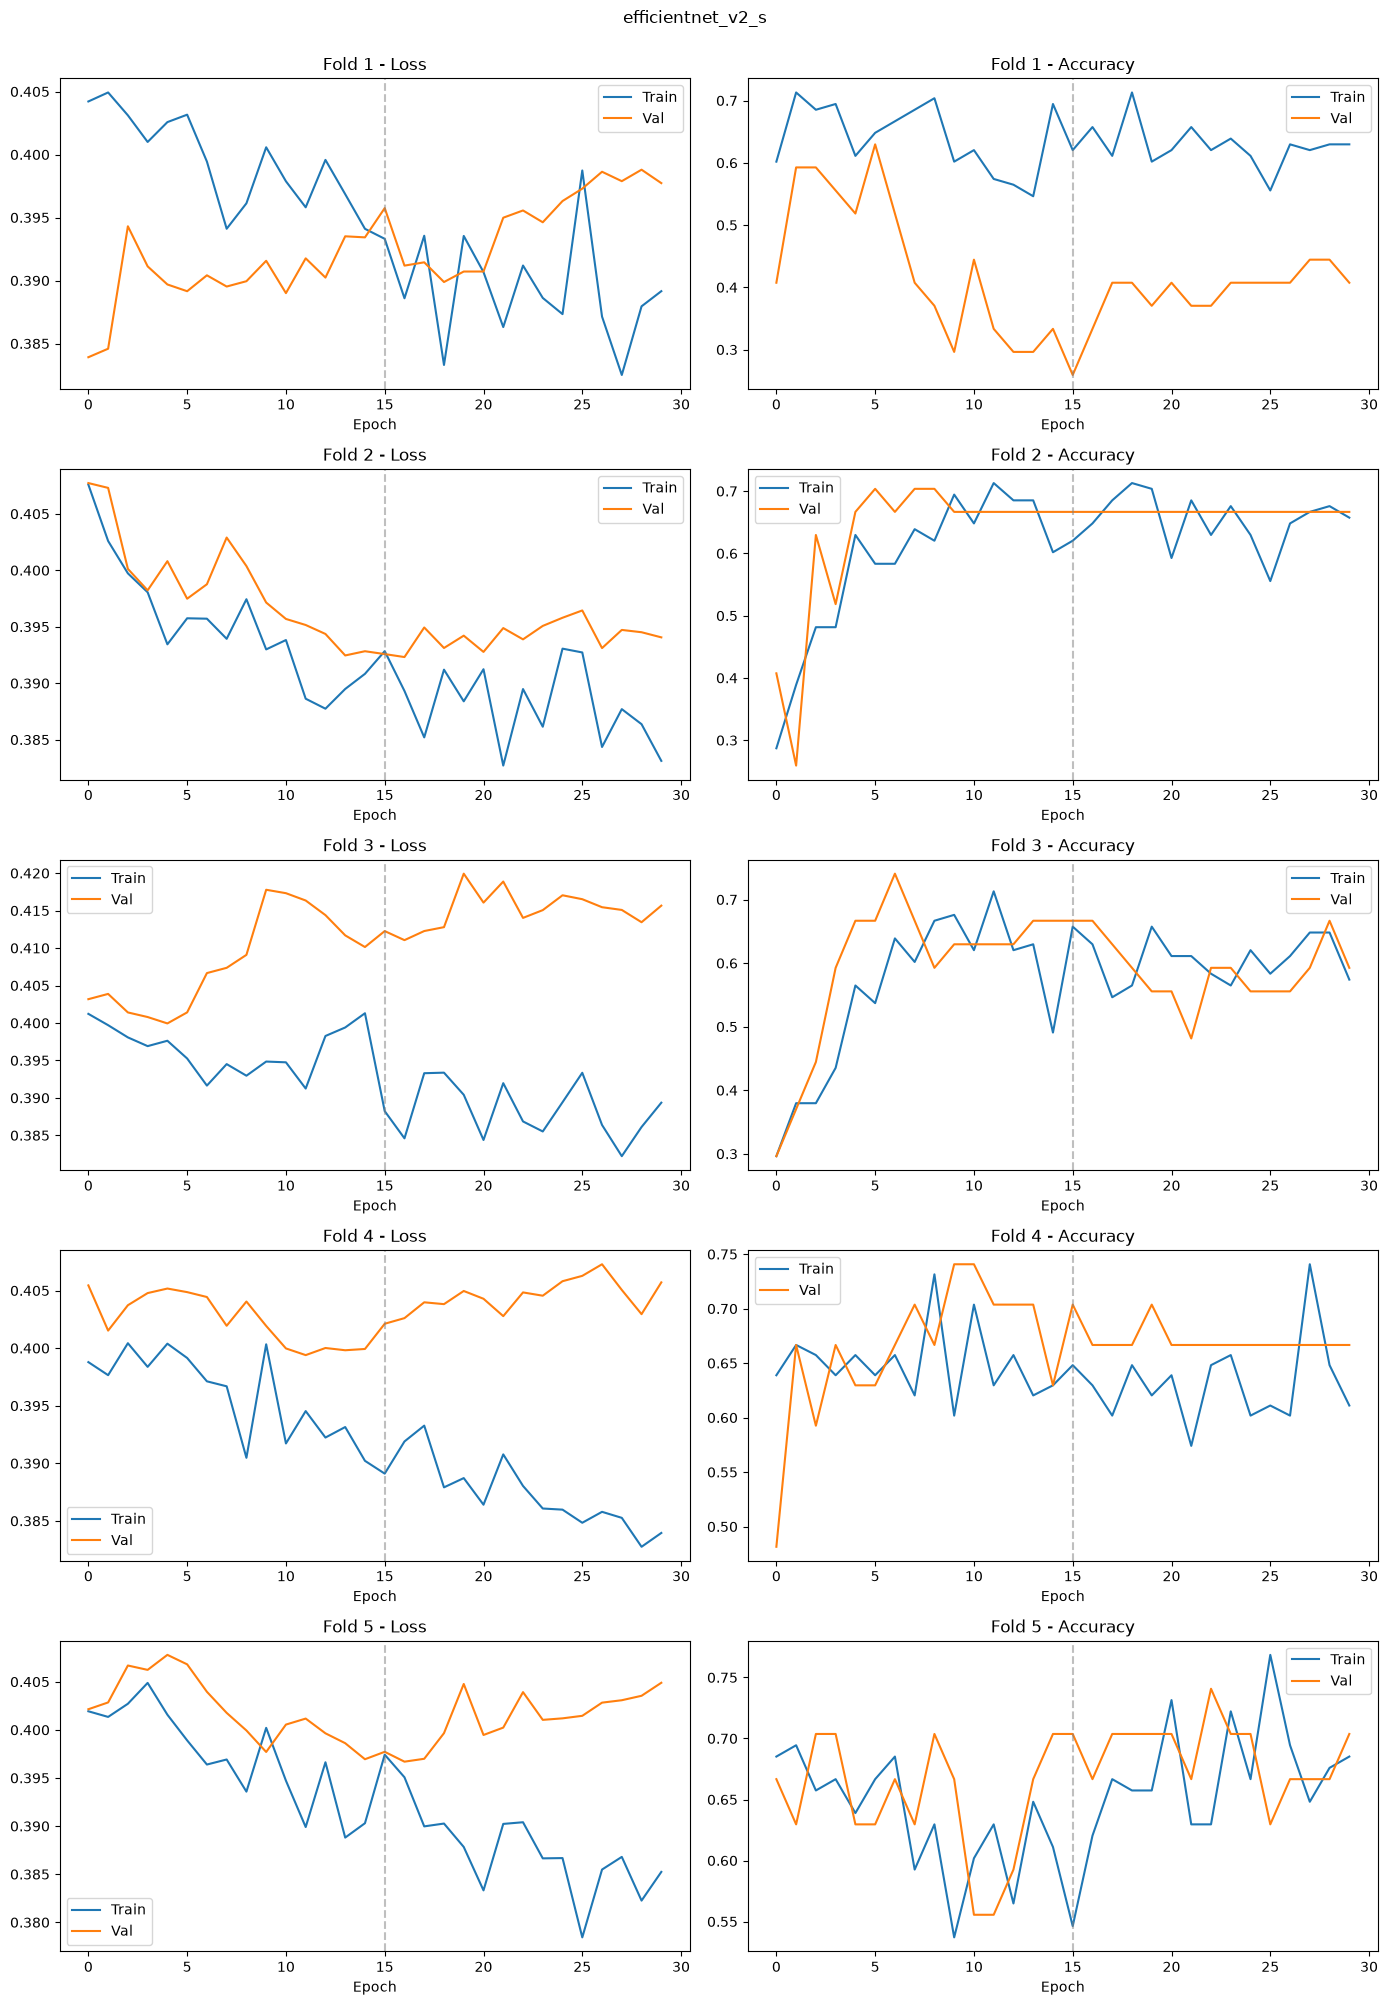

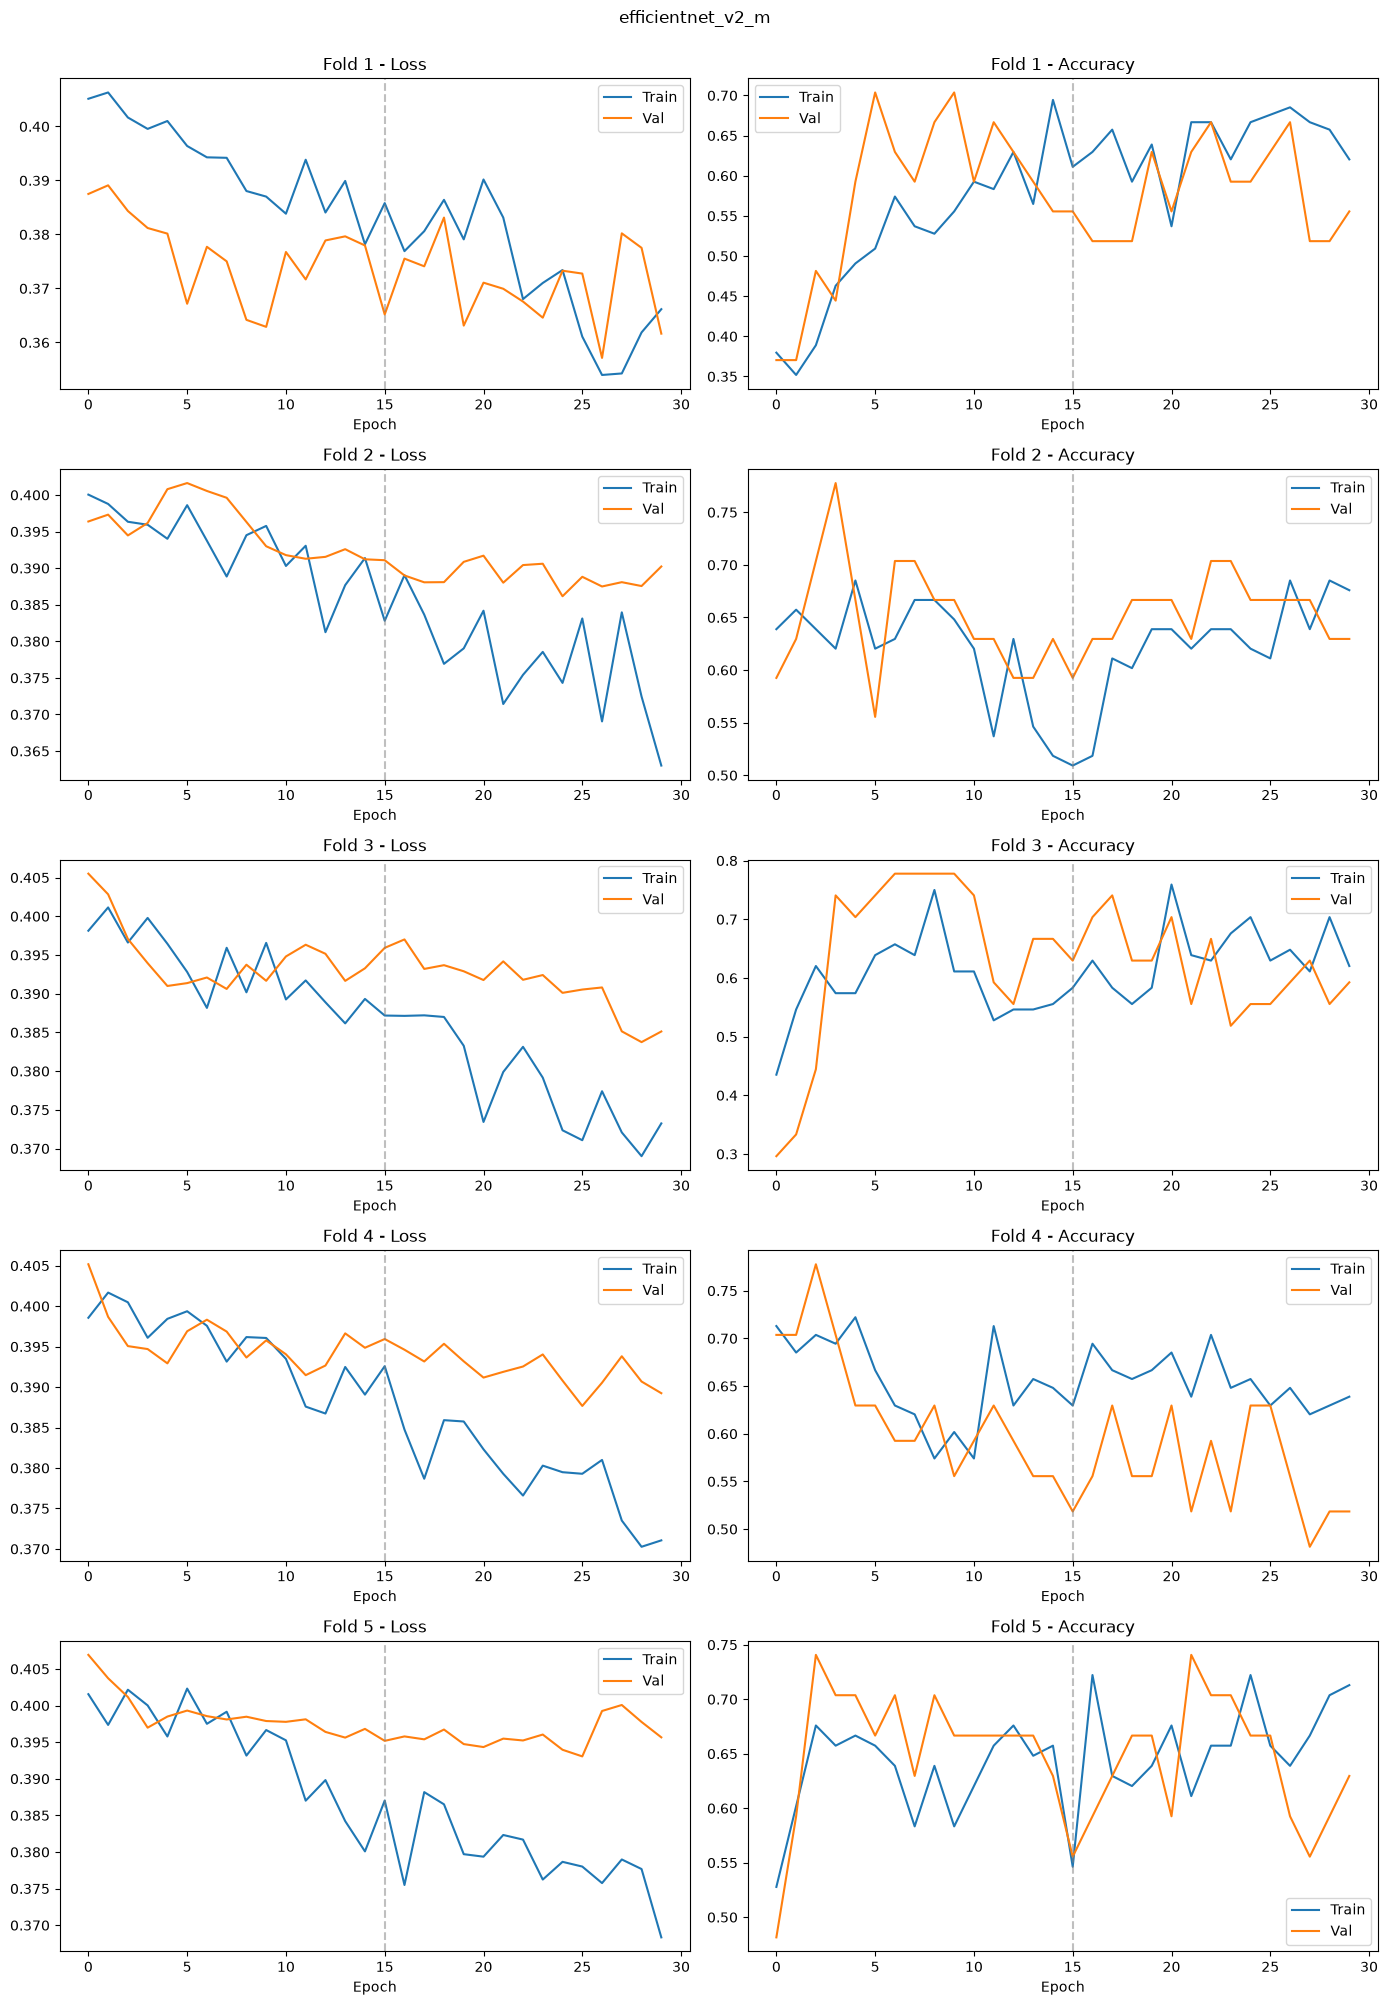

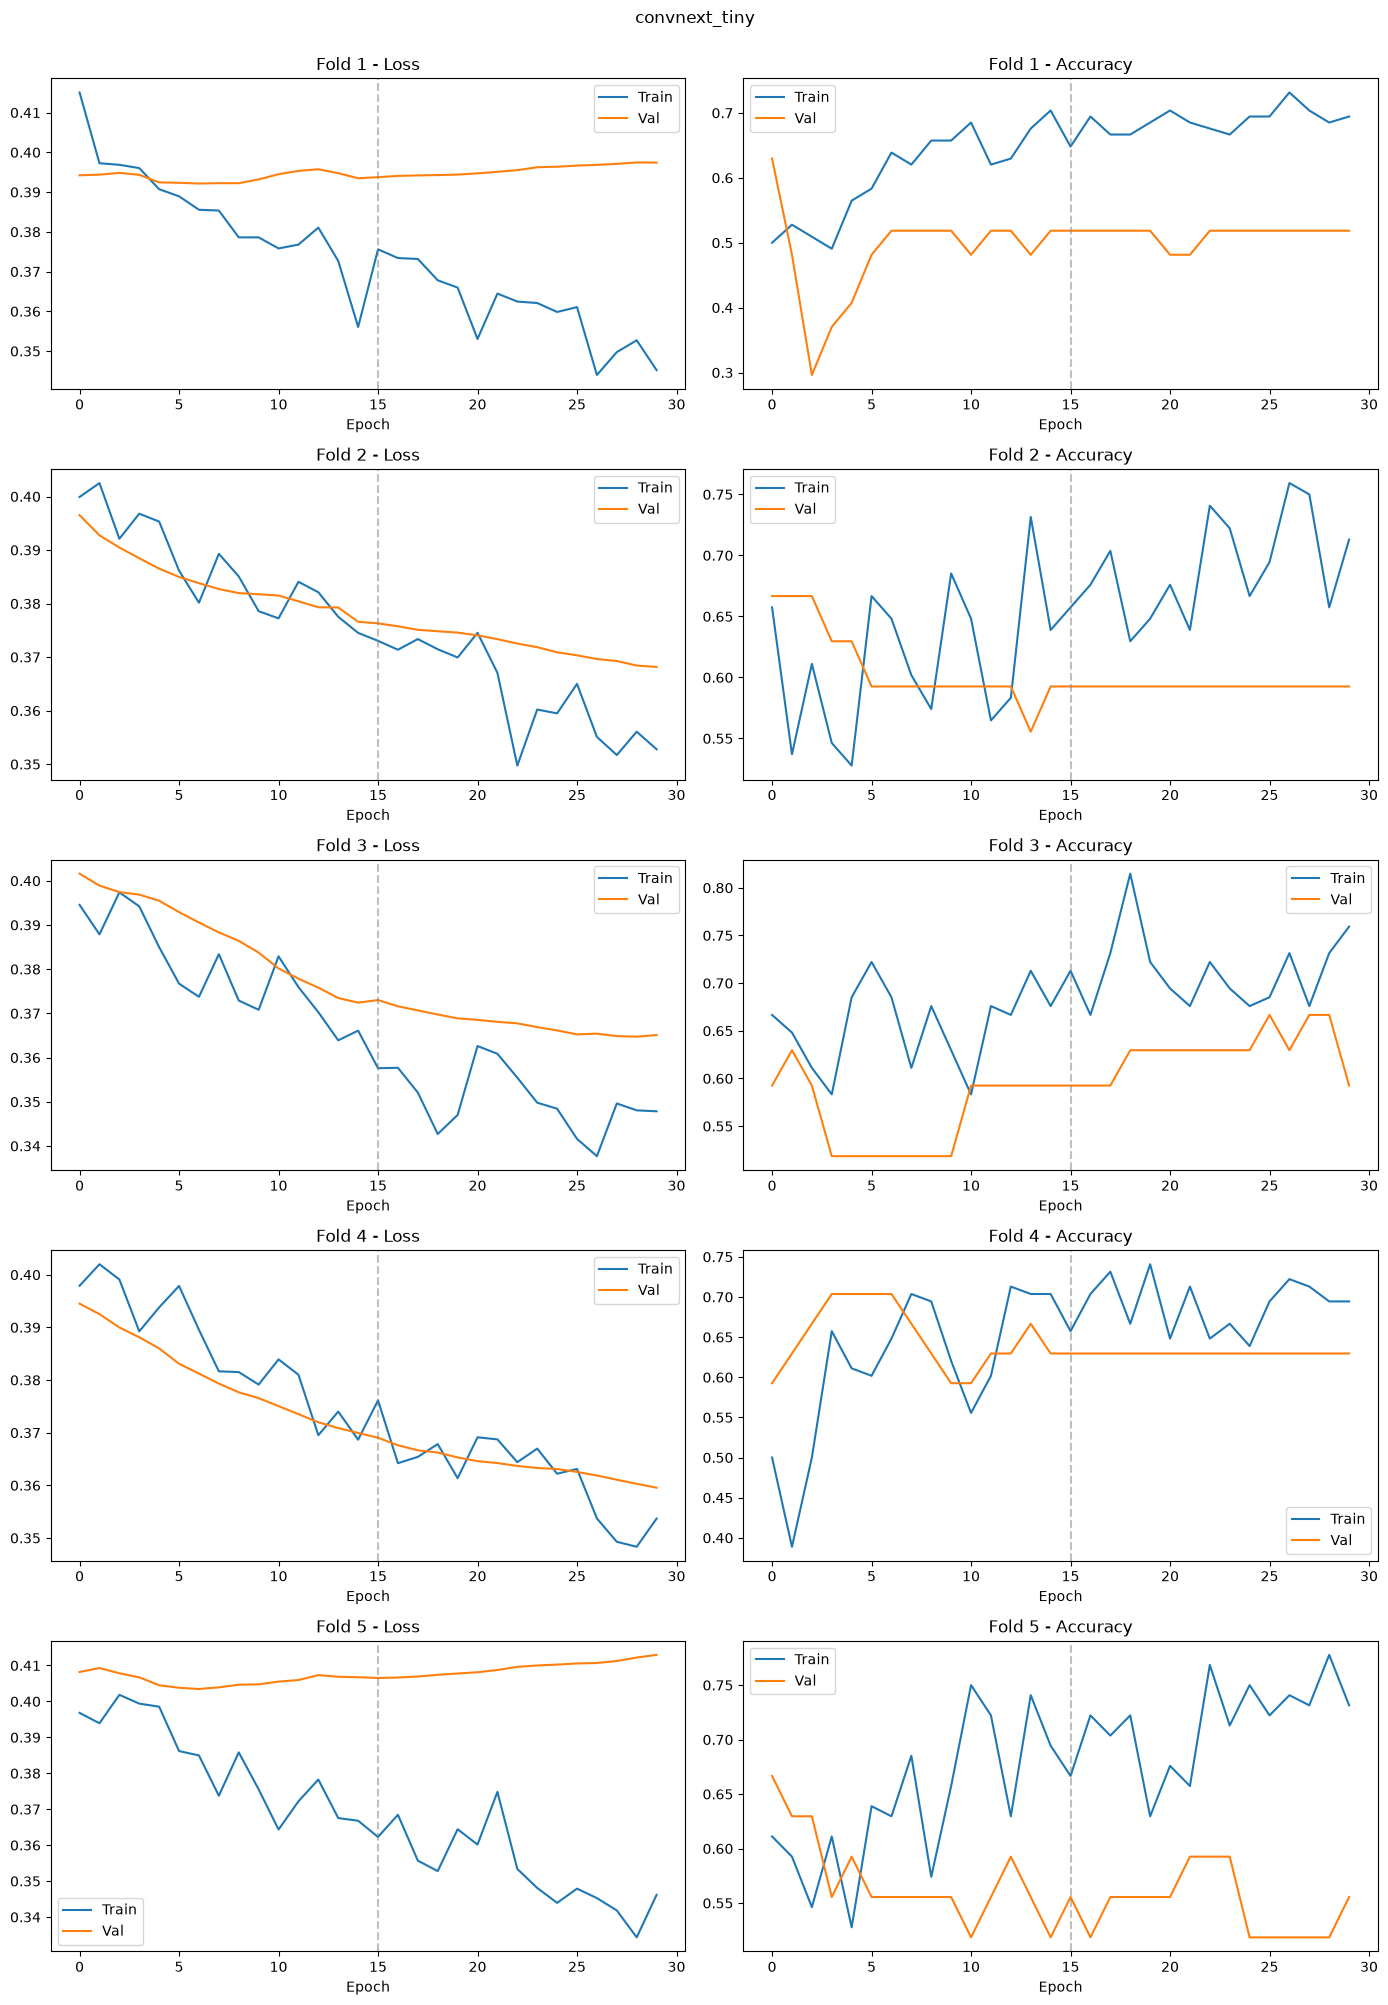

In [17]:
for name, result in results.items():
    fig, axes = plt.subplots(N_FOLDS, 2, figsize=(14, 4 * N_FOLDS))
    fig.suptitle(name, y=1.0)

    for i, history in enumerate(result["histories"]):
        axes[i, 0].plot(history["train_loss"], label="Train")
        axes[i, 0].plot(history["val_loss"], label="Val")
        axes[i, 0].set_title(f"Fold {i+1} - Loss")
        axes[i, 0].legend()
        axes[i, 0].set_xlabel("Epoch")
        axes[i, 0].axvline(x=UNFREEZE_AT_EPOCH, color='gray', linestyle='--', alpha=0.5, label='Unfreeze')

        axes[i, 1].plot(history["train_acc"], label="Train")
        axes[i, 1].plot(history["val_acc"], label="Val")
        axes[i, 1].set_title(f"Fold {i+1} - Accuracy")
        axes[i, 1].legend()
        axes[i, 1].set_xlabel("Epoch")
        axes[i, 1].axvline(x=UNFREEZE_AT_EPOCH, color='gray', linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/{name}/training_curves.png", dpi=150, bbox_inches='tight')
    plt.show()

## 9. Overall evaluation

Confusion matrix and classification report on the whole dataset (each image was predicted exactly once through the K-Fold).

efficientnet_v2_s - Classification Report (agrégé sur les 5 folds) :

              precision    recall  f1-score   support

   Incorrect       0.28      0.23      0.25        39
     Correct       0.71      0.76      0.73        96

    accuracy                           0.61       135
   macro avg       0.49      0.50      0.49       135
weighted avg       0.59      0.61      0.59       135



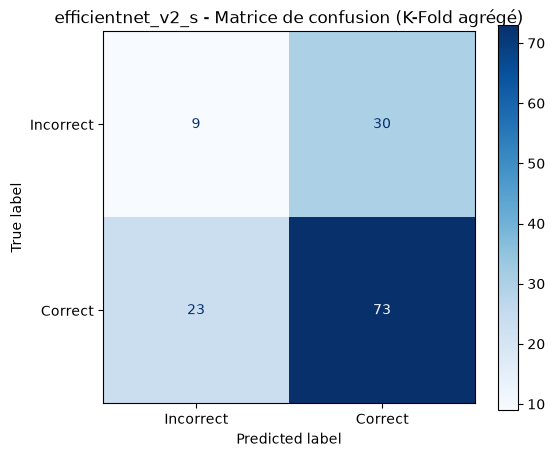

efficientnet_v2_m - Classification Report (agrégé sur les 5 folds) :

              precision    recall  f1-score   support

   Incorrect       0.35      0.51      0.42        39
     Correct       0.76      0.61      0.68        96

    accuracy                           0.59       135
   macro avg       0.55      0.56      0.55       135
weighted avg       0.64      0.59      0.60       135



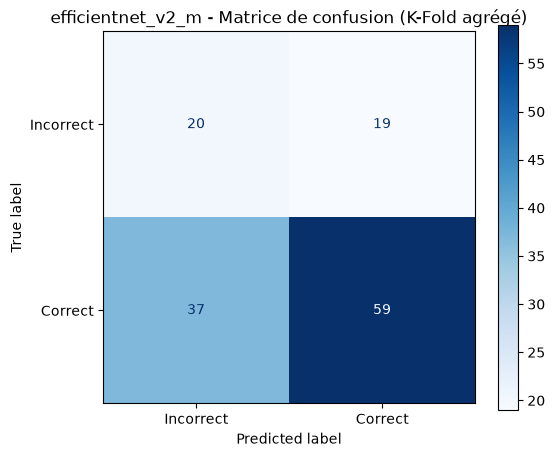

convnext_tiny - Classification Report (agrégé sur les 5 folds) :

              precision    recall  f1-score   support

   Incorrect       0.39      0.82      0.53        39
     Correct       0.87      0.48      0.62        96

    accuracy                           0.58       135
   macro avg       0.63      0.65      0.57       135
weighted avg       0.73      0.58      0.59       135



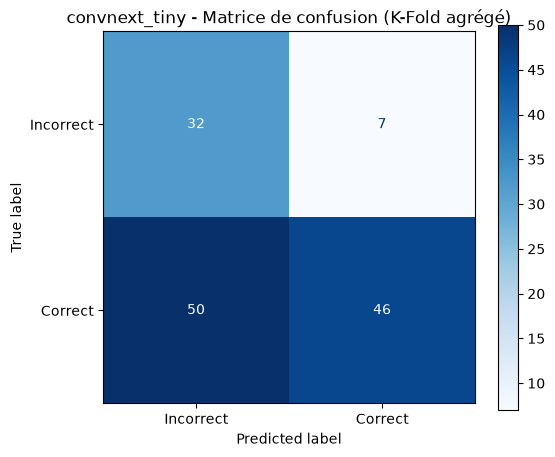

In [18]:
for name, result in results.items():
    print(f"{name} - Classification Report (aggregated over the {N_FOLDS} folds):\n")
    print(classification_report(y, result["preds"],
                                target_names=["Incorrect", "Correct"], zero_division=0))

    cm = confusion_matrix(y, result["preds"])
    disp = ConfusionMatrixDisplay(cm, display_labels=["Incorrect", "Correct"])
    fig, ax = plt.subplots(figsize=(6, 5))
    disp.plot(ax=ax, cmap='Blues')
    plt.title(f"{name} - Confusion matrix (aggregated K-Fold)")
    plt.savefig(f"{OUTPUT_DIR}/{name}/confusion_matrix.png", dpi=150, bbox_inches='tight')
    plt.show()

## 10. Model comparison

Each score is a mean over the folds ± its standard deviation. The **Baseline** row gives the score obtained by always answering "correct", without looking at the image: a useful model must do better.

Models are ranked on the **macro F1**, because accuracy alone favours the majority class. If the gap between two models is smaller than the standard deviations, it does not allow us to tell them apart.

In [19]:
METRIC_LABELS = {
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced accuracy",
    "f1_macro": "Macro F1",
    "recall_incorrect": "Recall (incorrect)",
}

fold_scores = {name: result["fold_metrics"] for name, result in results.items()}
fold_scores["Baseline (always correct)"] = [
    compute_metrics(y[val_idx], np.ones(len(val_idx))) for _, val_idx in FOLDS
]

comparison = pd.DataFrame({
    name: {
        label: f"{np.mean([m[key] for m in metrics]):.3f} ± {np.std([m[key] for m in metrics]):.3f}"
        for key, label in METRIC_LABELS.items()
    }
    for name, metrics in fold_scores.items()
}).T
comparison.to_csv(f"{OUTPUT_DIR}/comparison.csv", encoding="utf-8-sig")
display(comparison)

print("Macro F1 per fold:")
display(pd.DataFrame(
    {name: [m["f1_macro"] for m in metrics] for name, metrics in fold_scores.items()},
    index=[f"Fold {i+1}" for i in range(N_FOLDS)],
).round(3))

best_model_name = max(MODEL_NAMES, key=lambda name: np.mean([m["f1_macro"] for m in results[name]["fold_metrics"]]))
print(f"Best mean macro F1: {best_model_name}")

,Accuracy,Accuracy équilibrée,F1 macro,Rappel « incorrect »
efficientnet_v2_s,0.607 ± 0.106,0.498 ± 0.092,0.484 ± 0.104,0.232 ± 0.148
efficientnet_v2_m,0.585 ± 0.043,0.563 ± 0.065,0.545 ± 0.053,0.511 ± 0.129
convnext_tiny,0.578 ± 0.038,0.649 ± 0.073,0.568 ± 0.045,0.818 ± 0.190
Référence (toujours correct),0.711 ± 0.015,0.500 ± 0.000,0.416 ± 0.005,0.000 ± 0.000


F1 macro par fold :


,efficientnet_v2_s,efficientnet_v2_m,convnext_tiny,Référence (toujours correct)
Fold 1,0.365,0.500,0.508,0.426
Fold 2,0.585,0.616,0.593,0.413
Fold 3,0.372,0.553,0.593,0.413
Fold 4,0.486,0.472,0.625,0.413
Fold 5,0.614,0.583,0.524,0.413


Meilleur F1 macro moyen : convnext_tiny


## 11. Training the final model

We retrain **only the best model** on **all** the data (no validation split) to get the best possible model for deployment. The K-Fold gave the performance estimate; this model is the one we keep.

In [20]:
print(f"Training the final model ({best_model_name}) on all the data...")
set_seed()

full_ds = ExamDataset(X, y, augment=True)
full_loader = DataLoader(full_ds, batch_size=BATCH_SIZE, shuffle=True)

final_model = create_model(best_model_name, unfreeze_last_n=0)
criterion = make_criterion()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, final_model.parameters()), lr=LEARNING_RATE)

for epoch in range(EPOCHS):
    if epoch == UNFREEZE_AT_EPOCH:
        print(f"  → Unfreezing the last 2 blocks")
        for param in final_model.features[-2:].parameters():
            param.requires_grad = True
        optimizer = optim.Adam(filter(lambda p: p.requires_grad, final_model.parameters()), lr=LEARNING_RATE * 0.1)

    train_loss, train_acc = train_one_epoch(final_model, full_loader, criterion, optimizer)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"  Epoch {epoch+1:2d}/{EPOCHS} | Loss: {train_loss:.4f} | Acc: {train_acc:.3f}")

final_path = f"{OUTPUT_DIR}/{best_model_name}/final_model.pth"
torch.save(final_model.state_dict(), final_path)
print(f"\nFinal model saved to {final_path}")

Entraînement du modèle final (convnext_tiny) sur toutes les données...
  Epoch  1/30 | Loss: 0.4075 | Acc: 0.481
  Epoch  5/30 | Loss: 0.3892 | Acc: 0.541
  Epoch 10/30 | Loss: 0.3806 | Acc: 0.607
  Epoch 15/30 | Loss: 0.3644 | Acc: 0.719
  → Dégel des 2 derniers blocs
  Epoch 20/30 | Loss: 0.3687 | Acc: 0.659
  Epoch 25/30 | Loss: 0.3502 | Acc: 0.719
  Epoch 30/30 | Loss: 0.3508 | Acc: 0.711

Modèle final sauvegardé dans ../outputs/exercise_cnn/convnext_tiny/final_model.pth
